# BÁO CÁO KHÁM PHÁ VÀ TRỰC QUAN HÓA DỮ LIỆU (EDA)
## Đồ Án Môn Học: Khai Thác Dữ Liệu Truyền Thông Xã Hội (IE403)
### Đề tài: Phân Tích Cảm Xúc Đa Khía Cạnh (ABSA) Đánh Giá F&B Trên Google Maps

---

**Mục tiêu nghiên cứu của giai đoạn 3.EDA:**
1. **Khám phá và đánh giá chất lượng tập dữ liệu thô (Raw Data Profiling)**: Đánh giá 42.273 bản ghi đánh giá ẩm thực cào từ 1.500 cơ sở F&B tại Hà Nội và TP.HCM; nhận diện tỷ lệ khuyết thiếu (missing data) và sự mất cân bằng nghiêm trọng về số sao (class imbalance).
2. **Quy trình làm sạch dữ liệu (Data Cleaning & Normalization)**: Loại bỏ các chuỗi dịch tự động của Google, loại bỏ bình luận rác/quá ngắn, khử trùng lặp hoàn toàn nội dung bình luận.
3. **Ẩn danh hóa (Data Anonymization)**: Loại bỏ thông tin cá nhân của người đánh giá và liên kết định danh cá nhân nhằm đảm bảo đạo đức nghiên cứu, mã hóa cơ sở F&B thành `place_id`.
4. **Chiến lược lấy mẫu phân tầng cân bằng (Stratified Sampling - 10.000 dòng)**: Cân bằng hoàn hảo 3 nhóm cảm xúc chính (Tiêu cực, Trung tính, Tích cực) nhằm làm đầu vào tối ưu cho mô hình ngôn ngữ lớn (LLM Zero/Few-shot Labeling).
5. **Khảo sát đặc trưng ngôn ngữ tự nhiên (NLP Characteristics)**: Phân tích độ dài câu (chứng minh tính khả thi của ngưỡng `max_length=128` cho PhoBERT), thống kê tần suất từ lóng (Teencode) và biểu tượng cảm xúc (Emoji).
6. **Xây dựng bộ mẫu chuẩn đối chứng (Gold Standard - 200 mẫu)**: Thiết lập template đánh giá độc lập cho 4 thành viên (ẩn số sao) phục vụ kiểm định độ tin cậy liên người gán (Inter-Annotator Agreement - Fleiss' Kappa) và đối sánh với LLM.

In [1]:
import os
import re
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Thiết lập hiển thị tiếng Việt và thẩm mỹ đồ thị
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'Calibri', 'Tahoma', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

print("✅ Đã nạp thành công các thư viện phân tích dữ liệu và thiết lập đồ họa!")

✅ Đã nạp thành công các thư viện phân tích dữ liệu và thiết lập đồ họa!


---
## PHẦN 1: KHÁM PHÁ TẬP DỮ LIỆU THÔ (RAW DATASET PROFILING)

Tập dữ liệu thô được thu thập từ giai đoạn `2.Crawl_data/fnb_reviews_30_per_place.csv` bao gồm 42.273 đánh giá tương ứng với 1.500 địa điểm ẩm thực tại TP.HCM và Hà Nội.

In [2]:
raw_csv_path = "../2.Crawl_data/fnb_reviews_30_per_place.csv"
df_raw = pd.read_csv(raw_csv_path)

print(f"Tổng số dòng dữ liệu thô: {len(df_raw):,} dòng")
print(f"Tổng số cột: {df_raw.shape[1]} cột")
print("\nDanh sách các cột:")
for i, col in enumerate(df_raw.columns, 1):
    print(f"  {i}. {col} (Kiểu: {df_raw[col].dtype})")

df_raw.head(3)

Tổng số dòng dữ liệu thô: 42,273 dòng
Tổng số cột: 12 cột

Danh sách các cột:
  1. stt_quan (Kiểu: int64)
  2. ten_quan (Kiểu: str)
  3. thanh_pho (Kiểu: str)
  4. quan_huyen (Kiểu: str)
  5. phan_loai (Kiểu: str)
  6. google_maps_url (Kiểu: str)
  7. stt_review (Kiểu: int64)
  8. ten_reviewer (Kiểu: str)
  9. so_sao (Kiểu: float64)
  10. thoi_gian (Kiểu: str)
  11. noi_dung_review (Kiểu: str)
  12. so_luot_thich (Kiểu: int64)


In [3]:
null_counts = df_raw.isnull().sum()
null_pct = (null_counts / len(df_raw)) * 100
missing_df = pd.DataFrame({
    'Số lượng khuyết (NaN)': null_counts,
    'Tỷ lệ khuyết (%)': null_pct.round(3)
})
missing_df = missing_df[missing_df['Số lượng khuyết (NaN)'] > 0]
print("Bảng thống kê các trường bị khuyết thiếu trong tập thô:")
missing_df

Bảng thống kê các trường bị khuyết thiếu trong tập thô:


### Nhận định về chất lượng tập thô & Sự mất cân bằng số sao (Class Imbalance)
- Dữ liệu khuyết thiếu tập trung ở cột `so_sao` (240 dòng) và `noi_dung_review` (25 dòng). Do số lượng nhỏ (< 0.6%), việc loại bỏ các dòng này không làm ảnh hưởng đến tính toàn vẹn của mẫu.
- Hãy kiểm tra phân bố tần suất của cột `so_sao` để đánh giá mức độ thiên lệch cảm xúc của người dùng Google Maps.

In [4]:
star_counts = df_raw['so_sao'].dropna().value_counts().sort_index()
star_pct = (star_counts / star_counts.sum()) * 100

star_summary_raw = pd.DataFrame({
    'Số lượng đánh giá': star_counts,
    'Tỷ lệ phần trăm (%)': star_pct.round(2)
})
print("Phân bố số sao trong tập dữ liệu thô:")
display(star_summary_raw)

pos_raw_pct = star_pct.loc[[4.0, 5.0]].sum()
neg_raw_pct = star_pct.loc[[1.0, 2.0]].sum()
neu_raw_pct = star_pct.loc[3.0]
print(f"-> Tỷ lệ nhóm Tích cực (4-5 sao) : {pos_raw_pct:.2f}% (Chiếm áp đảo)")
print(f"-> Tỷ lệ nhóm Tiêu cực (1-2 sao) : {neg_raw_pct:.2f}%")
print(f"-> Tỷ lệ nhóm Trung tính (3 sao) : {neu_raw_pct:.2f}% (Rất khan hiếm)")

Phân bố số sao trong tập dữ liệu thô:
        Số lượng đánh giá  Tỷ lệ phần trăm (%)
so_sao                                        
1.0                  6009                14.30
2.0                  1752                 4.17
3.0                  3498                 8.32
4.0                  8976                21.35
5.0                 21798                51.86
-> Tỷ lệ nhóm Tích cực (4-5 sao) : 73.21% (Chiếm áp đảo)
-> Tỷ lệ nhóm Tiêu cực (1-2 sao) : 18.46%
-> Tỷ lệ nhóm Trung tính (3 sao) : 8.32% (Rất khan hiếm)


---
## PHẦN 2: QUY TRÌNH TIỀN XỬ LÝ & LẤY MẪU PHÂN TẦNG 10.000 DÒNG

Nhằm khắc phục hiện tượng mất cân bằng nhãn và loại bỏ tạp âm văn bản, quy trình tiền xử lý được thực hiện qua các giai đoạn nghiêm ngặt:
1. **Làm sạch văn bản**: Loại bỏ các nhãn tự động sinh bởi Google Maps như `(Dịch bởi Google)`, `(Translated by Google)`, `(Bản gốc)`, `(Original)`; chuẩn hóa khoảng trắng.
2. **Lọc chất lượng ngôn ngữ**: Loại bỏ bình luận dưới 4 từ hoặc chỉ chứa các ký tự đặc biệt/số, đảm bảo có chữ cái tiếng Việt/Latin.
3. **Khử trùng lặp**: Loại bỏ hoàn toàn các bình luận trùng lặp nội dung (`drop_duplicates`).
4. **Ẩn danh hóa**: Loại bỏ `ten_reviewer`, `google_maps_url`, mã hóa `stt_quan` sang `place_id` (P0001 -> P1500).
5. **Lấy mẫu phân tầng (Stratified Sampling)**: Lấy mẫu cân bằng 3 cực:
   - **Tiêu cực (1-2 sao)**: 3.333 mẫu.
   - **Trung tính (3 sao)**: 3.334 mẫu.
   - **Tích cực (4-5 sao)**: 3.333 mẫu.
   - Tổng cộng: Đúng 10.000 mẫu, sinh mã `id` từ `REV_00001` đến `REV_10000`.

In [5]:
dataset_10k_path = "dataset_10000_unlabeled.csv"
df_10k = pd.read_csv(dataset_10k_path)

print(f"Kích thước tập dữ liệu chuẩn: {df_10k.shape}")
print(f"Danh sách các trường thông tin:\n{df_10k.columns.tolist()}")

# Kiểm tra phân bố số sao trong tập chuẩn 10.000 dòng
star_counts_10k = df_10k['so_sao'].value_counts().sort_index()
star_summary_10k = pd.DataFrame({
    'Số lượng mẫu': star_counts_10k,
    'Tỷ lệ (%)': (star_counts_10k / len(df_10k) * 100).round(2)
})
print("\nPhân bố số sao sau khi lấy mẫu phân tầng:")
display(star_summary_10k)

# Kiểm tra tính cân bằng của 3 nhóm cảm xúc
def assign_sentiment_group(s):
    if s in [1.0, 2.0]:
        return "Tiêu cực (1-2 sao)"
    elif s == 3.0:
        return "Trung tính (3 sao)"
    else:
        return "Tích cực (4-5 sao)"

df_10k['sentiment_group'] = df_10k['so_sao'].apply(assign_sentiment_group)
group_summary = df_10k['sentiment_group'].value_counts()
print("\nTỷ lệ 3 nhóm cảm xúc trong tập 10.000 dòng:")
display(pd.DataFrame({'Số mẫu': group_summary, 'Tỷ lệ (%)': (group_summary / len(df_10k) * 100).round(2)}))

Kích thước tập dữ liệu chuẩn: (10000, 9)
Danh sách các trường thông tin:
['id', 'place_id', 'thanh_pho', 'quan_huyen', 'phan_loai', 'so_sao', 'thoi_gian', 'so_luot_thich', 'noi_dung_review']

Phân bố số sao sau khi lấy mẫu phân tầng:
        Số lượng mẫu  Tỷ lệ (%)
so_sao                         
1.0             2546      25.46
2.0              787       7.87
3.0             3334      33.34
4.0              991       9.91
5.0             2342      23.42

Tỷ lệ 3 nhóm cảm xúc trong tập 10.000 dòng:
                    Số mẫu  Tỷ lệ (%)
sentiment_group                      
Trung tính (3 sao)    3334      33.34
Tiêu cực (1-2 sao)    3333      33.33
Tích cực (4-5 sao)    3333      33.33


---
## PHẦN 3: TRỰC QUAN HÓA & ĐỐI SÁNH DỮ LIỆU CHUYÊN SÂU

Chúng ta tiến hành khảo sát và đối sánh 4 khía cạnh trọng tâm:
1. So sánh phân bố số sao trước và sau khi lấy mẫu phân tầng.
2. Phân tích phân bố độ dài từ (Word Count) và kiểm chứng ngưỡng `max_length=128` cho mô hình Transformer (PhoBERT).
3. Khảo sát đặc trưng ngôn ngữ mạng: Từ lóng (Teencode) và Biểu tượng cảm xúc (Emoji).
4. Phân bố không gian địa lý (TP.HCM vs Hà Nội) và phân loại hình thức ẩm thực.

### 3.1. So sánh phân bố số sao (Star Distribution Comparison)
Hình ảnh bên dưới thể hiện rõ sự chuyển đổi từ tập dữ liệu thô bị thiên lệch nặng (skewed) sang tập dữ liệu cân bằng hoàn hảo giữa 3 nhóm cảm xúc.

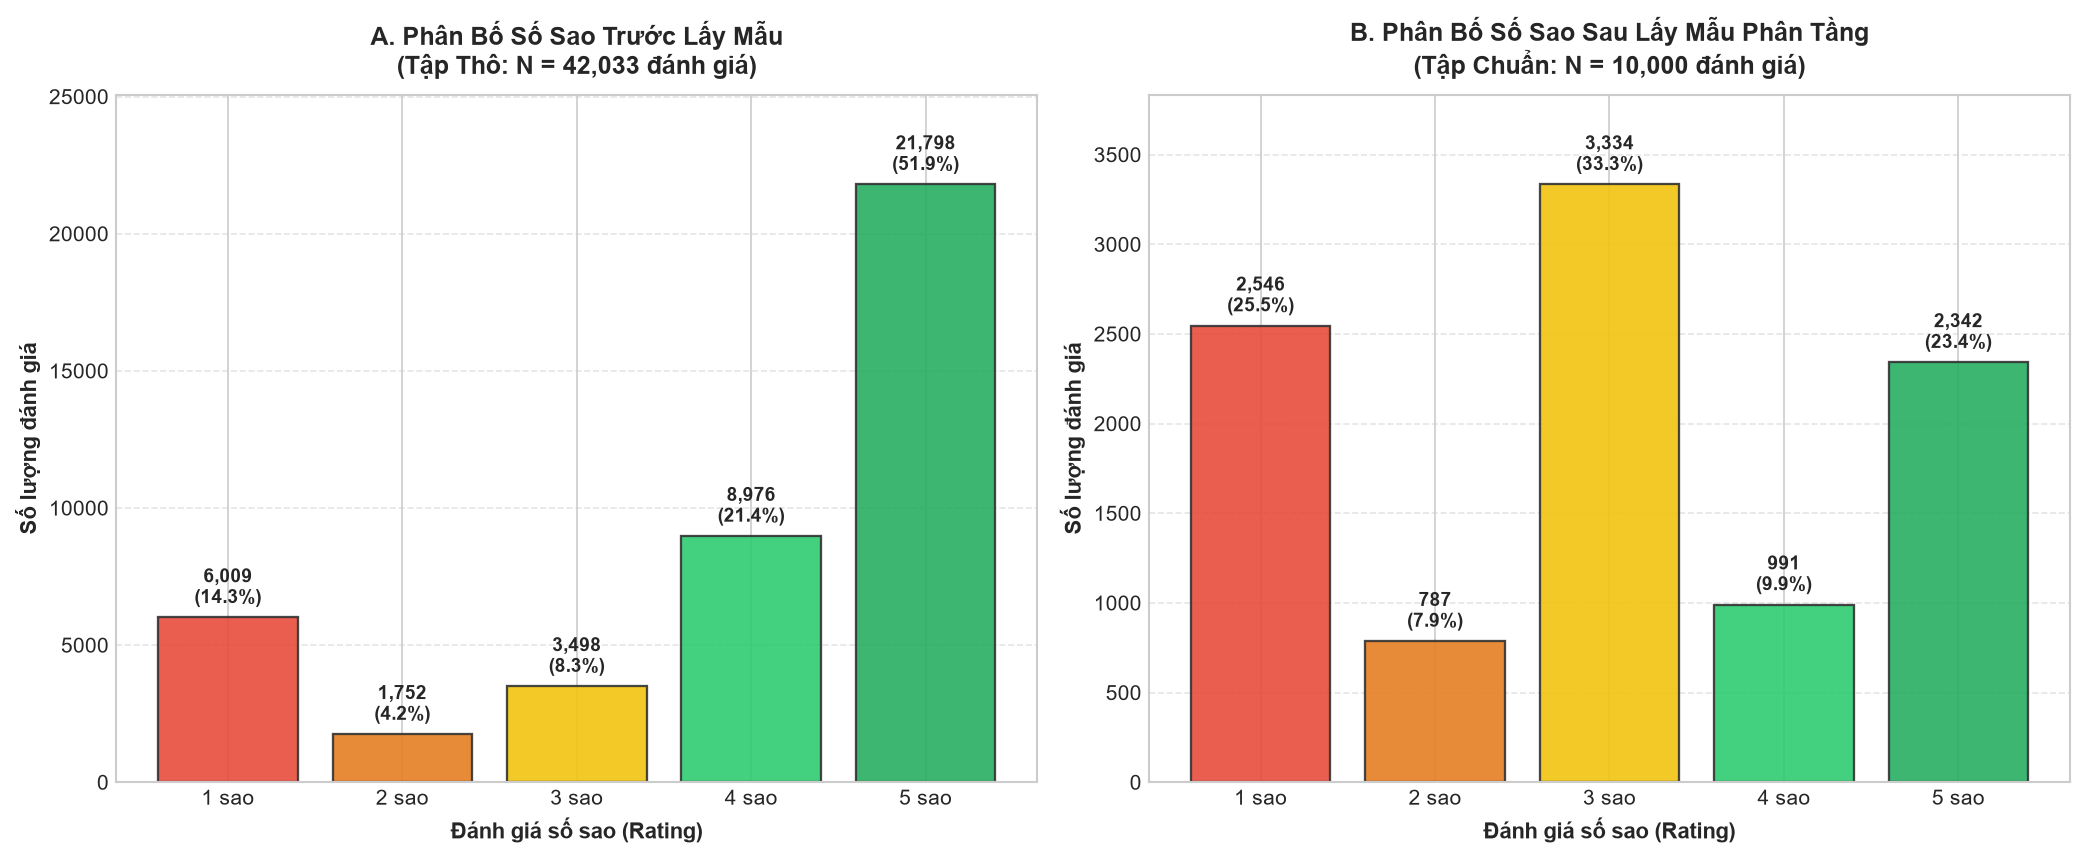

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
palette = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#27ae60']

# A. Tập thô
raw_stars = df_raw['so_sao'].dropna().value_counts().sort_index()
total_raw = len(df_raw['so_sao'].dropna())
raw_pct = (raw_stars / total_raw) * 100

bars1 = axes[0].bar([f"{int(s)} sao" for s in raw_stars.index], raw_stars.values, color=palette, edgecolor='#333', linewidth=1.1, alpha=0.9)
axes[0].set_title(f"A. Phân Bố Số Sao Trước Lấy Mẫu\n(Tập Thô: N = {total_raw:,} đánh giá)", fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel("Đánh giá số sao (Rating)", fontsize=10.5, fontweight='bold')
axes[0].set_ylabel("Số lượng đánh giá", fontsize=10.5, fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

for bar, count, pct in zip(bars1, raw_stars.values, raw_pct.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2., bar.get_height() + max(raw_stars.values) * 0.015,
                 f"{count:,}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[0].set_ylim(0, max(raw_stars.values) * 1.15)

# B. Tập 10k
s_stars = df_10k['so_sao'].value_counts().sort_index()
total_10k = len(df_10k)
s_pct = (s_stars / total_10k) * 100

bars2 = axes[1].bar([f"{int(s)} sao" for s in s_stars.index], s_stars.values, color=palette, edgecolor='#333', linewidth=1.1, alpha=0.9)
axes[1].set_title(f"B. Phân Bố Số Sao Sau Lấy Mẫu Phân Tầng\n(Tập Chuẩn: N = {total_10k:,} đánh giá)", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel("Đánh giá số sao (Rating)", fontsize=10.5, fontweight='bold')
axes[1].set_ylabel("Số lượng đánh giá", fontsize=10.5, fontweight='bold')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

for bar, count, pct in zip(bars2, s_stars.values, s_pct.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2., bar.get_height() + max(s_stars.values) * 0.015,
                 f"{count:,}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[1].set_ylim(0, max(s_stars.values) * 1.15)

plt.tight_layout()
plt.show()

### 3.2. Phân tích độ dài bình luận (Word Count) & Luận cứ chọn ngưỡng `max_length=128` cho PhoBERT

Trong các mô hình Transformer như PhoBERT (`vinai/phobert-base-v2`), độ phức tạp tính toán của cơ chế Self-Attention tỷ lệ thuận với bình phương độ dài chuỗi đầu vào ($O(L^2)$). Việc chọn `max_length` là sự đánh đổi (trade-off) quan trọng giữa:
1. **Khả năng bao phủ ngữ cảnh**: Tránh bị cắt cụt (truncation) làm mất đi các khía cạnh nhận xét quan trọng ở cuối câu.
2. **Chi phí tính toán và bộ nhớ GPU**: Chiều dài chuỗi càng lớn thì bộ nhớ GPU tiêu hao càng cao, làm giảm batch size và kéo dài thời gian huấn luyện.

Dưới đây là thực nghiệm đo lường phân bố độ dài từ thực tế trên 10.000 đánh giá:

--- BÁO CÁO THỐNG KÊ ĐỘ DÀI TỪ ---
• Độ dài từ trung bình (Mean)   : 61.23 từ
• Trung vị (Median)             : 42 từ
• Điểm phân vị thứ 90 (P90)     : 125.0 từ
• Điểm phân vị thứ 95 (P95)     : 181.0 từ
• Tỷ lệ bình luận <= 128 từ     : 90.51%


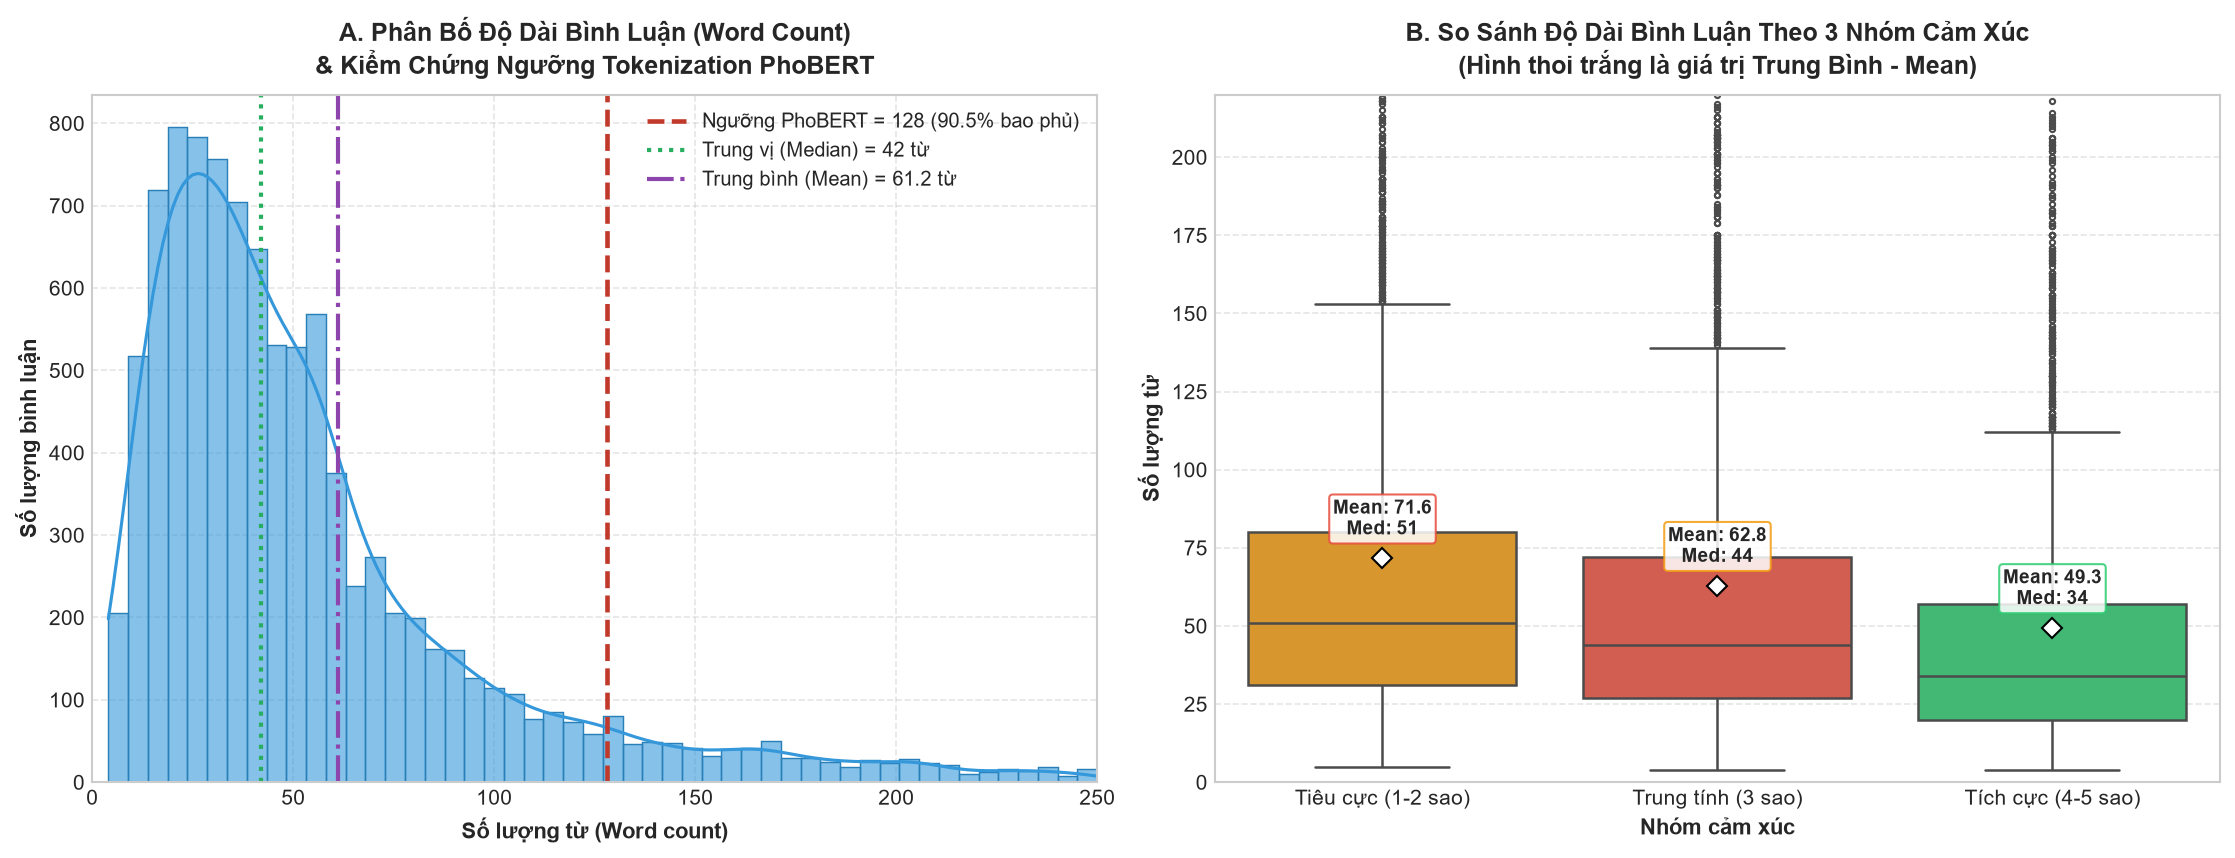

In [7]:
df_10k['word_count'] = df_10k['noi_dung_review'].apply(lambda x: len(str(x).split()))

mean_wc = df_10k['word_count'].mean()
median_wc = df_10k['word_count'].median()
p90_wc = np.percentile(df_10k['word_count'], 90)
p95_wc = np.percentile(df_10k['word_count'], 95)
pct_128 = (df_10k['word_count'] <= 128).mean() * 100

print(f"--- BÁO CÁO THỐNG KÊ ĐỘ DÀI TỪ ---")
print(f"• Độ dài từ trung bình (Mean)   : {mean_wc:.2f} từ")
print(f"• Trung vị (Median)             : {median_wc:.0f} từ")
print(f"• Điểm phân vị thứ 90 (P90)     : {p90_wc:.1f} từ")
print(f"• Điểm phân vị thứ 95 (P95)     : {p95_wc:.1f} từ")
print(f"• Tỷ lệ bình luận <= 128 từ     : {pct_128:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))

# Subplot 1: Histogram & KDE
wc_plot = df_10k['word_count'][df_10k['word_count'] <= 250]
sns.histplot(wc_plot, bins=50, kde=True, ax=axes[0], color='#3498db', edgecolor='#2980b9', alpha=0.6)
axes[0].axvline(128, color='#c0392b', linestyle='--', linewidth=2.2, label=f'Ngưỡng PhoBERT = 128 ({pct_128:.1f}% bao phủ)')
axes[0].axvline(median_wc, color='#27ae60', linestyle=':', linewidth=2, label=f'Trung vị (Median) = {median_wc:.0f} từ')
axes[0].axvline(mean_wc, color='#8e44ad', linestyle='-.', linewidth=2, label=f'Trung bình (Mean) = {mean_wc:.1f} từ')

axes[0].set_title("A. Phân Bố Độ Dài Bình Luận (Word Count)\n& Kiểm Chứng Ngưỡng Tokenization PhoBERT", fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel("Số lượng từ (Word count)", fontsize=10.5, fontweight='bold')
axes[0].set_ylabel("Số lượng bình luận", fontsize=10.5, fontweight='bold')
axes[0].set_xlim(0, 250)
axes[0].legend(loc='upper right', fontsize=9.5)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Boxplot theo nhóm cảm xúc
group_order = ["Tiêu cực (1-2 sao)", "Trung tính (3 sao)", "Tích cực (4-5 sao)"]
group_colors = ['#e74c3c', '#f39c12', '#2ecc71']

sns.boxplot(
    x='sentiment_group', y='word_count', hue='sentiment_group', legend=False,
    data=df_10k, order=group_order, palette=group_colors, ax=axes[1],
    showmeans=True, meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 6.5},
    fliersize=2.5, linewidth=1.2
)
axes[1].set_title("B. So Sánh Độ Dài Bình Luận Theo 3 Nhóm Cảm Xúc\n(Hình thoi trắng là giá trị Trung Bình - Mean)", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel("Nhóm cảm xúc", fontsize=10.5, fontweight='bold')
axes[1].set_ylabel("Số lượng từ", fontsize=10.5, fontweight='bold')
axes[1].set_ylim(0, 220)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

grp_stats = df_10k.groupby('sentiment_group')['word_count'].agg(['mean', 'median']).loc[group_order]
for idx, (grp, row) in enumerate(grp_stats.iterrows()):
    axes[1].text(idx, row['mean'] + 6, f"Mean: {row['mean']:.1f}\nMed: {row['median']:.0f}",
                 ha='center', va='bottom', fontsize=9, fontweight='bold',
                 bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor=group_colors[idx], alpha=0.85))

plt.tight_layout()
plt.show()

### Phân tích chuyên sâu về hành vi đánh giá của người tiêu dùng:
1. **Sự tương phản về độ dài giữa các nhóm cảm xúc**:
   - **Nhóm Tiêu cực (1-2 sao)**: Có độ dài trung bình lớn nhất (**71.59 từ**, trung vị **51.0 từ**). Người dùng khi bức xúc có xu hướng tường thuật chi tiết từng trải nghiệm tiêu cực: thái độ nhân viên, tốc độ phục vụ, vấn đề vệ sinh, sự chênh lệch giá cả...
   - **Nhóm Trung tính (3 sao)**: Độ dài trung bình **62.80 từ**, trung vị **44.0 từ**. Bình luận thường chứa cấu trúc khen chê tương phản ("Đồ ăn ngon nhưng nhân viên phục vụ chậm").
   - **Nhóm Tích cực (4-5 sao)**: Độ dài ngắn nhất (**49.30 từ**, trung vị **34.0 từ**). Người dùng thường để lại những lời khen ngắn gọn, mang tính cảm thán ("Quán xinh, đồ uống ngon", "5 sao cho dịch vụ").
2. **Khuyến nghị kiến trúc cho mô hình Transformer**:
   - Ngưỡng **128 từ** bao phủ tới **90.51%** toàn bộ tập dữ liệu.
   - Đối với các bài toán Fine-tuning PhoBERT, việc đặt `max_length=128` giúp giữ trọn vẹn ngữ cảnh của hơn 90% số đánh giá trong khi tiết kiệm đáng kể thời gian huấn luyện và bộ nhớ GPU so với cấu hình `max_length=256`.

### 3.3. Đặc trưng ngôn ngữ mạng: Từ lóng (Teencode) và Biểu tượng cảm xúc (Emoji)

Văn phong mạng xã hội và đánh giá trực tuyến của người tiêu dùng trẻ tại Việt Nam mang đậm các đặc trưng:
- Sử dụng dày đặc từ viết tắt / từ lóng: `ko`, `k`, `đc`, `dc`, `nv`, `vs`, `bth`, `oke`, `mik`...
- Sử dụng Emoji để nhấn mạnh sắc thái cảm xúc hoặc thay thế từ ngữ.

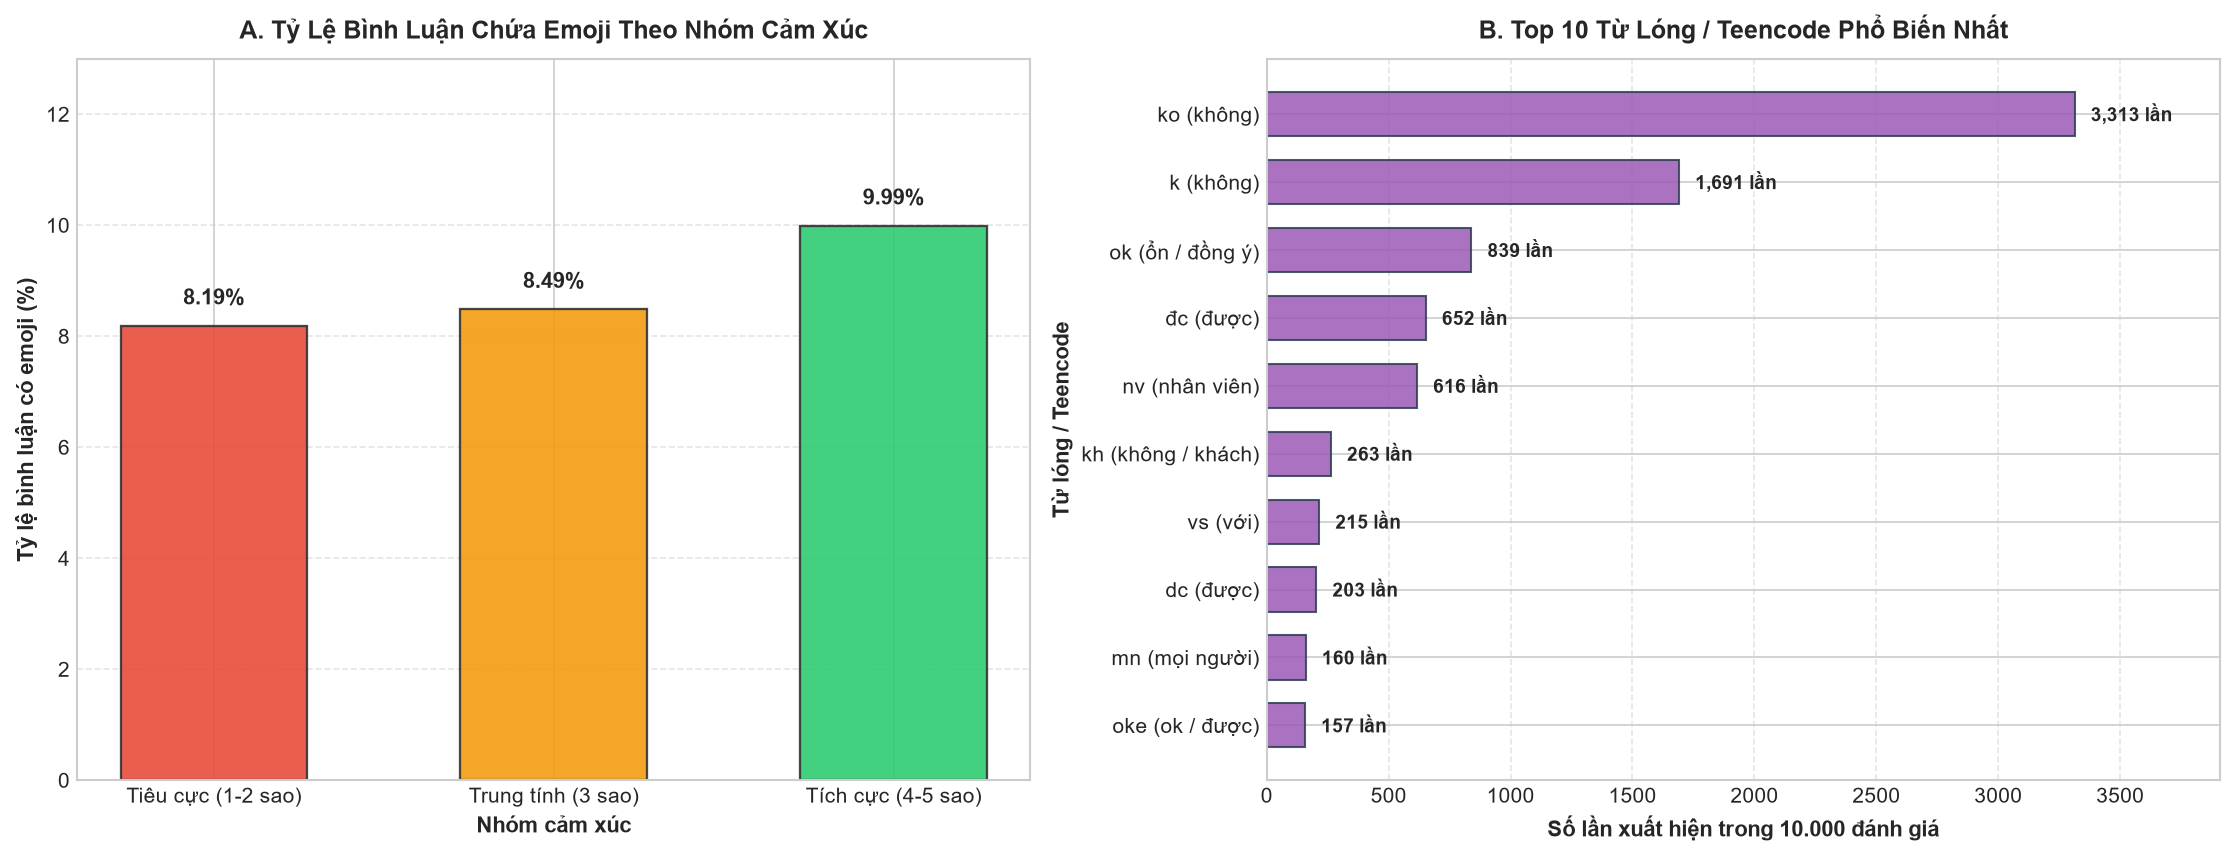

In [8]:
# 1. Thống kê tỷ lệ Emoji
emoji_pattern = re.compile(r'[𐀀-􏿿☀-➿]')
df_10k['has_emoji'] = df_10k['noi_dung_review'].apply(lambda x: bool(emoji_pattern.search(str(x))))
emoji_rates = df_10k.groupby('sentiment_group')['has_emoji'].mean() * 100
emoji_rates = emoji_rates.loc[group_order]

# 2. Thống kê Teencode Top 10
teencode_dict = {
    'ko (không)': r'\bko\b',
    'k (không)': r'\bk\b',
    'ok (ổn / đồng ý)': r'\bok\b',
    'đc (được)': r'\bđc\b',
    'nv (nhân viên)': r'\bnv\b',
    'kh (không / khách)': r'\bkh\b',
    'vs (với)': r'\bvs\b',
    'dc (được)': r'\bdc\b',
    'mn (mọi người)': r'\bmn\b',
    'oke (ok / được)': r'\boke\b'
}

tc_counts = []
for label, pat in teencode_dict.items():
    regex = re.compile(pat, re.IGNORECASE)
    occ = df_10k['noi_dung_review'].apply(lambda t: len(regex.findall(str(t)))).sum()
    tc_counts.append({'label': label, 'count': occ})

df_tc = pd.DataFrame(tc_counts).sort_values(by='count', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))

# Subplot 1: Tỷ lệ Emoji
bars_em = axes[0].bar(emoji_rates.index, emoji_rates.values, color=group_colors, edgecolor='#333', linewidth=1.1, alpha=0.9, width=0.55)
axes[0].set_title("A. Tỷ Lệ Bình Luận Chứa Emoji Theo Nhóm Cảm Xúc", fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel("Nhóm cảm xúc", fontsize=10.5, fontweight='bold')
axes[0].set_ylabel("Tỷ lệ bình luận có emoji (%)", fontsize=10.5, fontweight='bold')
axes[0].set_ylim(0, max(emoji_rates.values) * 1.3)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

for bar, val in zip(bars_em, emoji_rates.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.3, f"{val:.2f}%",
                 ha='center', va='bottom', fontsize=10.5, fontweight='bold')

# Subplot 2: Top 10 Teencode
bars_tc = axes[1].barh(df_tc['label'], df_tc['count'], color='#9b59b6', edgecolor='#2c3e50', linewidth=1, alpha=0.85, height=0.65)
axes[1].set_title("B. Top 10 Từ Lóng / Teencode Phổ Biến Nhất", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel("Số lần xuất hiện trong 10.000 đánh giá", fontsize=10.5, fontweight='bold')
axes[1].set_ylabel("Từ lóng / Teencode", fontsize=10.5, fontweight='bold')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)
axes[1].set_xlim(0, max(df_tc['count']) * 1.18)

for bar in bars_tc:
    w = bar.get_width()
    axes[1].text(w + max(df_tc['count']) * 0.02, bar.get_y() + bar.get_height() / 2.,
                 f"{int(w):,} lần", ha='left', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### 3.4. Phân bố không gian địa lý và phân loại ẩm thực
Khảo sát sự cân bằng giữa hai trung tâm kinh tế lớn là Hà Nội và TP.HCM cùng các quận huyện trọng điểm.

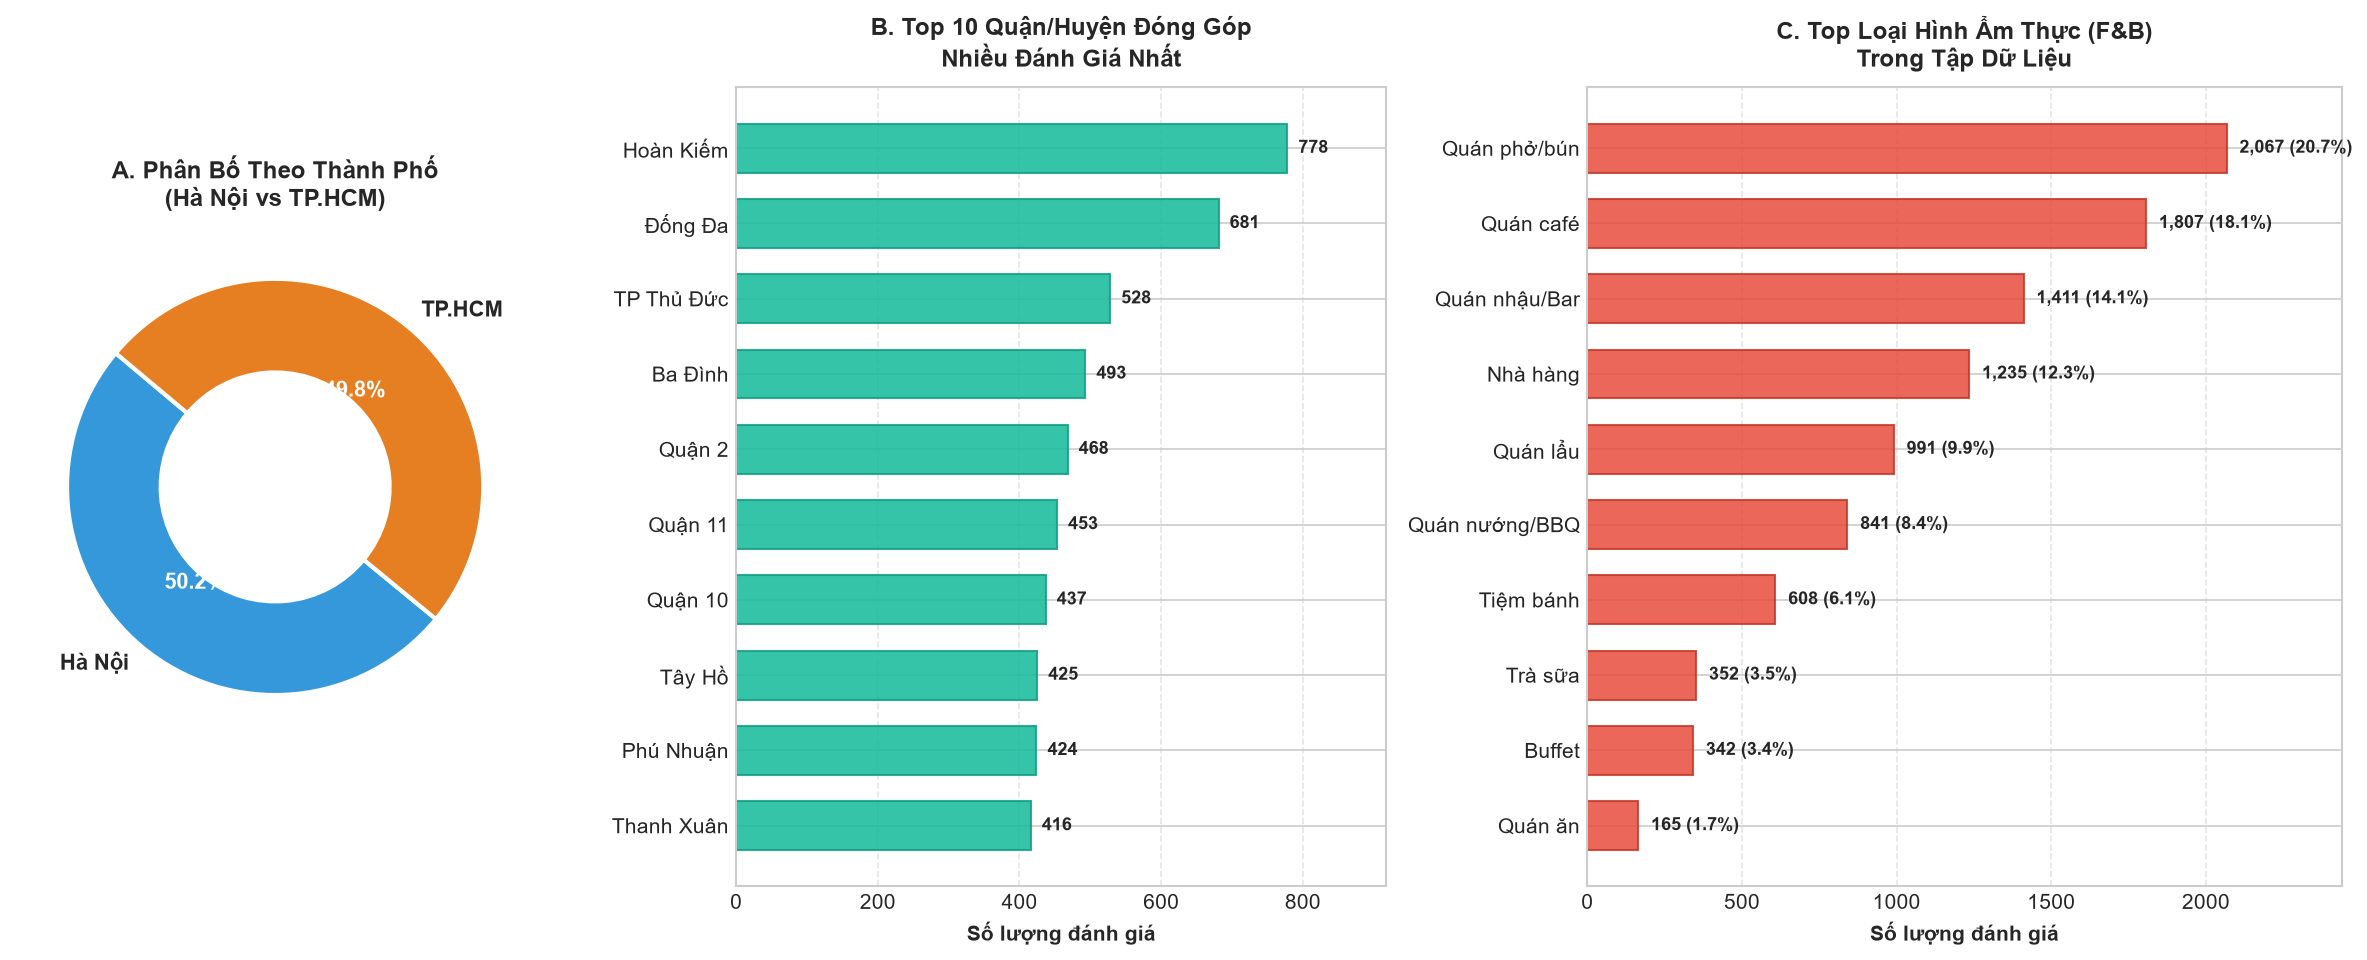

In [9]:
fig = plt.figure(figsize=(16, 6.5))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.25, 1.45])

ax_city = fig.add_subplot(gs[0])
ax_dist = fig.add_subplot(gs[1])
ax_cat = fig.add_subplot(gs[2])

# A. Phân bố Thành phố
city_counts = df_10k['thanh_pho'].value_counts()
wedges, texts, autotexts = ax_city.pie(
    city_counts.values, labels=city_counts.index, autopct='%1.1f%%',
    startangle=140, colors=['#3498db', '#e67e22'],
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    textprops=dict(fontsize=10.5, fontweight='bold')
)
for at in autotexts:
    at.set_color('white')
    at.set_weight('bold')
ax_city.set_title("A. Phân Bố Theo Thành Phố\n(Hà Nội vs TP.HCM)", fontsize=11.5, fontweight='bold', pad=10)

# B. Top 10 Quận / Huyện
top_dist = df_10k['quan_huyen'].value_counts().head(10).sort_values(ascending=True)
bars_dist = ax_dist.barh(top_dist.index, top_dist.values, color='#1abc9c', edgecolor='#16a085', linewidth=1, alpha=0.88, height=0.65)
ax_dist.set_title("B. Top 10 Quận/Huyện Đóng Góp\nNhiều Đánh Giá Nhất", fontsize=11.5, fontweight='bold', pad=10)
ax_dist.set_xlabel("Số lượng đánh giá", fontsize=10, fontweight='bold')
ax_dist.grid(axis='x', linestyle='--', alpha=0.5)
ax_dist.set_xlim(0, max(top_dist.values) * 1.18)

for bar in bars_dist:
    w = bar.get_width()
    ax_dist.text(w + max(top_dist.values) * 0.02, bar.get_y() + bar.get_height() / 2.,
                 f"{int(w):,}", ha='left', va='center', fontsize=8.5, fontweight='bold')

# C. Top Phân loại ẩm thực
top_cat = df_10k['phan_loai'].value_counts().head(10).sort_values(ascending=True)
bars_cat = ax_cat.barh(top_cat.index, top_cat.values, color='#e74c3c', edgecolor='#c0392b', linewidth=1, alpha=0.85, height=0.65)
ax_cat.set_title("C. Top Loại Hình Ẩm Thực (F&B)\nTrong Tập Dữ Liệu", fontsize=11.5, fontweight='bold', pad=10)
ax_cat.set_xlabel("Số lượng đánh giá", fontsize=10, fontweight='bold')
ax_cat.grid(axis='x', linestyle='--', alpha=0.5)
ax_cat.set_xlim(0, max(top_cat.values) * 1.18)

for bar in bars_cat:
    w = bar.get_width()
    pct = (w / len(df_10k)) * 100
    ax_cat.text(w + max(top_cat.values) * 0.02, bar.get_y() + bar.get_height() / 2.,
                f"{int(w):,} ({pct:.1f}%)", ha='left', va='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

---
## PHẦN 4: KHẢO SÁT TẬP MẪU CHUẨN ĐỐI CHỨNG (GOLD STANDARD 200 MẪU)

File `gold_standard_200_template.csv` được trích xuất phân tầng từ tập 10.000 dòng theo tỷ lệ:
- **Tiêu cực (1-2 sao)**: 66 mẫu
- **Trung tính (3 sao)**: 68 mẫu
- **Tích cực (4-5 sao)**: 66 mẫu

**Nguyên tắc thiết kế phục vụ gán nhãn khoa học:**
1. **Ẩn cột `so_sao`**: Đảm bảo 4 thành viên gán nhãn hoàn toàn dựa trên ngữ nghĩa văn bản (Human-in-the-loop), không bị tác động tâm lý bởi xếp hạng sao của người dùng.
2. **Cấu trúc cột chuẩn hóa**: Cung cấp sẵn các trường `sentiment_1`, `is_mixed_1` đến `sentiment_4`, `is_mixed_4` để từng thành viên điền độc lập, sau đó tính hệ số đồng thuận **Fleiss' Kappa** và **Cohen's Kappa** đối chứng với LLM.

In [10]:
gold_path = "gold_standard_200_template.csv"
df_gold = pd.read_csv(gold_path)

print(f"Kích thước tập Gold Standard: {df_gold.shape}")
print(f"Cột `so_sao` có trong file không? -> {'so_sao' in df_gold.columns} (Đã ẩn hoàn toàn)")
print("\nDanh sách các cột trong Gold Standard:")
print(df_gold.columns.tolist())

# Hiển thị 3 mẫu đầu tiên của template
df_gold[['id', 'place_id', 'thanh_pho', 'phan_loai', 'noi_dung_review', 'sentiment_1', 'is_mixed_1']].head(3)

Kích thước tập Gold Standard: (200, 16)
Cột `so_sao` có trong file không? -> False (Đã ẩn hoàn toàn)

Danh sách các cột trong Gold Standard:
['id', 'place_id', 'thanh_pho', 'quan_huyen', 'phan_loai', 'thoi_gian', 'so_luot_thich', 'noi_dung_review', 'sentiment_1', 'is_mixed_1', 'sentiment_2', 'is_mixed_2', 'sentiment_3', 'is_mixed_3', 'sentiment_4', 'is_mixed_4']


---
## PHẦN 5: KẾT LUẬN VÀ KẾ HOẠCH GIAI ĐOẠN TIẾP THEO

### 1. Tổng kết các kết quả đạt được từ EDA:
- **Dữ liệu sạch & An toàn**: Đã loại bỏ 100% các dòng khuyết thiếu, khử trùng lặp, lọc các nhận xét rác/quá ngắn và ẩn danh hóa thông tin cá nhân.
- **Giải quyết triệt để Class Imbalance**: Xây dựng thành công tập 10.000 dòng phân tầng cân bằng 3 cực cảm xúc (33.33% - 33.34% - 33.33%), triệt tiêu hoàn toàn bias lệch về 5 sao của tập thô ban đầu.
- **Xác lập tham số mô hình hóa**: Chứng minh ngưỡng `max_length=128` cho PhoBERT là tối ưu về mặt chi phí và bao phủ >90.5% bình luận.
- **Đặc trưng ngôn ngữ**: Thống kê danh mục Teencode (`ko`, `k`, `đc`, `nv`, `vs`...) và Emoji, đặt nền móng cho việc xây dựng từ điển chuẩn hóa văn bản ở giai đoạn gán nhãn và huấn luyện.

### 2. Kế hoạch triển khai giai đoạn 4 (LLM Labeling & Fine-tuning):
1. **Annotation với 4 Annotator**: 4 thành viên tiến hành gán nhãn độc lập trên `gold_standard_200_template.csv`.
2. **Kiểm định Inter-Annotator Agreement**: Tính toán Fleiss' Kappa giữa 4 thành viên.
3. **Prompt Engineering & LLM Zero/Few-shot**: Thiết kế prompt hướng dẫn mô hình ngôn ngữ lớn (Gemini 1.5 Flash / GPT-4o-mini) gán nhãn 10.000 mẫu trên các khía cạnh (Chất lượng đồ ăn, Dịch vụ, Giá cả, Không gian, Vệ sinh).
4. **Đối chứng & Đánh giá**: Tính Cohen's Kappa giữa nhãn đồng thuận của con người và nhãn sinh bởi LLM trên tập 200 mẫu.